In [ ]:
## TODO: All project members will need to pip install rasterio 

import torch
import numpy as np
import pandas as pd
import rasterio
import torch.nn as nn
from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader, Subset
from sklearn.dummy import DummyClassifier
from sklearn.metrics import classification_report, accuracy_score
import plotly.graph_objects as go
from IPython.display import display
from torchvision import models
from torch import optim
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from torchmetrics.classification import MulticlassConfusionMatrix

ModuleNotFoundError: No module named 'torch'

In [ ]:
DIR_PATH = "../EuroSATallBands/"

#dataloader class
class EuroSATDataset(Dataset):
    def __init__(self, csv_file, stats_file="normalization_stats.txt"):
        df = pd.read_csv(DIR_PATH + csv_file)

        self.files = df.iloc[:, 0].tolist()
        #make sure the class IDs are parsed as an int
        self.labels = df.iloc[:, 1].astype(int).tolist()
        stats = np.loadtxt(stats_file)

        self.band_mean = stats[:, 0].astype(np.float32)
        self.band_std = stats[:, 1].astype(np.float32)

    def __len__(self):
        return len(self.files)

    def __getitem__(self, index):
        filename = DIR_PATH + self.files[index]
        #must use rasterio to import the satellite TIF
        with rasterio.open(filename) as img:
            image = img.read().astype(np.float32)
            image = (image - self.band_mean[:, None, None]) / (self.band_std[:, None, None] + 1e-8)


        X = torch.from_numpy(image)
        #this is needed for CrossEntropyLoss later
        Y = torch.tensor(self.labels[index], dtype = torch.int)

        return X, Y

#default parameters: batch size 32, no max, do not shuffle, no workers, random seed of 2 for consistency
def make_dataloader(csv_file, batchsize=32, max_samples = None, shuffle = False, numWorkers = 0, seed = 2):
    r"""
    A function to create a Torch dataloader on a dataset or a subset of a dataset.

    Args:
        csv_file (string): The name of the csv file to be read. Expected format is filepath, classID, className
        batchsize (integer): The size of the batches to load
        max_samples (integer): Default(None) - How many samples to include in the dataloader
        shuffle (boolean): Default(False) - Whether or not the dataloader entires should be shuffled
        numWorkers (integer): Default(0) - How many concurrent workers should be run
        seed(integer): Default(2) - The RNG seed

    """
    dataset = EuroSATDataset(csv_file)
    #This is for splitting the data into smaller subsets so we don't have to train on the whole dataset
    if max_samples is not None:
        if max_samples < 1:
            raise ValueError("Maximum number of records must be positive")

        #for consistency in comparing models
        rng = torch.Generator().manual_seed(seed)
        indices = torch.randperm(dataset.__len__(), generator = rng)[:max_samples].tolist()

        dataset = Subset(dataset, indices)

    return DataLoader(dataset,
                      batch_size = batchsize, 
                      shuffle = shuffle, 
                      num_workers = numWorkers, 
                      pin_memory = torch.cuda.is_available(), 
                      persistent_workers = numWorkers > 0)


In [ ]:
# small dataset for model testing
# train_loader = make_dataloader(
#     "train.csv",
#     batchsize=32,
#     max_samples=1000,
#     shuffle=True
# )

# valid_loader = make_dataloader(
#     "validation.csv",
#     batchsize=32,
#     max_samples=200
# )

# test_loader = make_dataloader(
#     "test.csv",
#     batchsize=32,
# )
# full dataset
train_loader = make_dataloader(
    "train.csv",
    batchsize=32,
    shuffle=True
)

valid_loader = make_dataloader(
    "validation.csv",
    batchsize=32,
)

test_loader = make_dataloader(
    "test.csv",
    batchsize=32,
)

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')

Using device: cuda


In [ ]:
class model(torch.nn.Module):
    def __init__(self, pretrained_model):
        super(model, self).__init__() # Superclass constructor
        #pretrained part of model from ResNet
        self.encoder = pretrained_model

        #fully connected decoder part
        self.layer1 = torch.nn.Linear(2048, 256)
        self.layer2 = torch.nn.Linear(256, 64)
        self.layer3 = torch.nn.Linear(64, 10)

        # Activation
        self.relu = torch.nn.ReLU()
        
    def forward(self, X):
        CNNOutput = self.encoder(X)

        #fully connected section
        a0 = self.layer1(CNNOutput)
        a0 = self.relu(a0)
        a1 = self.layer2(a0)
        a1 = self.relu(a1)
        a2 = self.layer3(a1)

        return a2


In [ ]:
#import ResNet50 to be the encoder of our model
pretrained_ResNet = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
pretrained_ResNet.fc = nn.Identity()
originalFirstConv = pretrained_ResNet.conv1
#ResNet's default input channels is 3, so we must change it to 13 for our satellite images, we don't want to change anything else

#TODO: Fix the following line to not overwrite the input channels but to instead to as intended

pretrained_ResNet.conv1 = nn.Conv2d(13, originalFirstConv.out_channels, originalFirstConv.kernel_size, originalFirstConv.stride, originalFirstConv.padding, originalFirstConv.dilation, originalFirstConv.groups, originalFirstConv.bias)
#freeze weights of ResNet for now
for param in pretrained_ResNet.parameters():
    param.requires_grad = False

#create our model
SatelliteImageClassifier = model(pretrained_ResNet)
#make sure our whole model runs on same device
SatelliteImageClassifier = SatelliteImageClassifier.to(device)
costFunction = torch.nn.CrossEntropyLoss()

def train_model(model, trainloader, costFunction, optimizer, numEpochs):
    training_losses = []
    validation_losses = []
    best_valid_loss = float('inf')
    fig = go.FigureWidget()
    fig.add_trace(go.Scatter(x=list(range(len(training_losses))), y=training_losses, mode='lines', name='Training Loss'))
    fig.add_trace(go.Scatter(x=list(range(len(validation_losses))), y=validation_losses, mode='lines', name='Validation Loss'))
    fig.update_layout(title="Training and Validation Loss Over Time", xaxis_title="Epoch", yaxis_title="Loss")
    display(fig)
    for epoch in tqdm(range(numEpochs),desc="Epochs",unit="Epoch"):
        totalLoss = 0
        for satimgs, labels in tqdm(trainloader,desc="Training",unit="Batch"):
            satimgs = satimgs.to(device)
            labels = labels.to(device).long()

            #forward
            outputs = model(satimgs)
            loss = costFunction(outputs, labels)

            #backpropigation
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            #keep track of loss
            totalLoss += loss.item()
        
        #display loss every epoch
        avg_loss = totalLoss / len(train_loader)
        training_losses.append(avg_loss)

        model.eval()
        with torch.no_grad():
            valid_loss_tot = 0
            for img, label in tqdm(valid_loader,desc="Validation", unit="Batch"):
                output = model(img.to(device))
                loss = costFunction(output,label.to(device).long())
                valid_loss_tot += loss.item() * len(label)
            avg_valid_loss = valid_loss_tot / len(valid_loader.dataset)
            if avg_valid_loss < best_valid_loss:
                best_valid_loss = avg_valid_loss
                torch.save(model.state_dict(), "best_resnet50.pth")
            validation_losses.append(avg_valid_loss)       

        with fig.batch_update():
            fig.data[0].x = list(range(1, len(training_losses) + 1))
            fig.data[0].y = training_losses

            fig.data[1].x = list(range(1, len(validation_losses) + 1))
            fig.data[1].y = validation_losses

            fig.update_xaxes(autorange=True)
            fig.update_yaxes(autorange=True)


NameError: name 'models' is not defined

In [ ]:
from finetune import finetune_model

SatelliteImageClassifier, history = finetune_model(
    model=SatelliteImageClassifier,
    trainloader=train_loader,
    validloader=valid_loader,
    costFunction=costFunction,
    numEpochs=6,
    learning_rate=1e-4,
    encoder_lr=1e-5,
    save_path="best_resnet50.pth",
    device=device
)

ModuleNotFoundError: No module named 'torch'

In [ ]:

def get_labels(dataloader):
    """A function for retrieving the labels from a Dataloader or Subset"""
    dataset = dataloader.dataset
    #if max samples are specified, the dataloader gets a subset, which has a slightly different way to get to the labels
    if isinstance(dataset, Subset):
        labels = np.array(dataset.dataset.labels)[dataset.indices]
    else:
        labels = np.array(dataset.labels)
    return labels



#Model baseline:
Y_Train = get_labels(train_loader)
Y_Test = get_labels(test_loader)
#Scikit baseline doesn't actually use X but needs it specified, so a zero matrix is created
#to avoid loading the images into memory
X_Train = np.zeros((len(Y_Train), 1))
X_Test = np.zeros((len(Y_Test), 1))

baseline = DummyClassifier(strategy="stratified",random_state=2)
baseline.fit(X_Train,Y_Train)
Y_Pred = baseline.predict(X_Test)

print("----[Stratified Random Baseline]----")
print("Accuracy:", accuracy_score(Y_Test, Y_Pred))
print(classification_report(Y_Test,Y_Pred,zero_division=0))

----[Stratified Random Baseline]----
Accuracy: 0.09749909387459224
              precision    recall  f1-score   support

           0       0.12      0.12      0.12       300
           1       0.09      0.09      0.09       300
           2       0.12      0.13      0.12       300
           3       0.09      0.09      0.09       250
           4       0.04      0.04      0.04       250
           5       0.05      0.06      0.05       200
           6       0.11      0.11      0.11       250
           7       0.10      0.10      0.10       300
           8       0.12      0.12      0.12       250
           9       0.11      0.11      0.11       359

    accuracy                           0.10      2759
   macro avg       0.09      0.10      0.10      2759
weighted avg       0.10      0.10      0.10      2759



In [ ]:
def test_model(model, test_loader, costFunction):
    model.eval()

    loss_sum = 0
    total = 0
    all_predictions = []
    all_labels = []

    metric = MulticlassConfusionMatrix(num_classes=10).to(device)

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Testing"):
            images = images.to(device)
            labels = labels.to(device).long()

            outputs = model(images)
            loss = costFunction(outputs, labels)

            predictions = outputs.argmax(dim=1)

            loss_sum += loss.item() * len(labels)
            total += len(labels)

            # Update confusion matrix for all batches
            metric.update(predictions, labels)

            # Save predictions for classification report
            all_predictions.extend(predictions.cpu().tolist())
            all_labels.extend(labels.cpu().tolist())

    avg_loss = loss_sum / total
    cm = metric.compute().cpu().numpy()

    accuracy = np.trace(cm) / np.sum(cm)

    print(f"Test Loss: {avg_loss:.4f}")
    print(f"Test Accuracy: {accuracy * 100:.2f}%")

    return cm, avg_loss, accuracy, all_labels, all_predictions

    Label             ClassName
5       0            AnnualCrop
18      1                Forest
0       2  HerbaceousVegetation
13      3               Highway
11      4            Industrial
55      5               Pasture
20      6         PermanentCrop
2       7           Residential
3       8                 River
4       9               SeaLake


Testing:   0%|          | 0/87 [00:00<?, ?it/s]

Test Loss: 0.7239
Test Accuracy: 76.44%


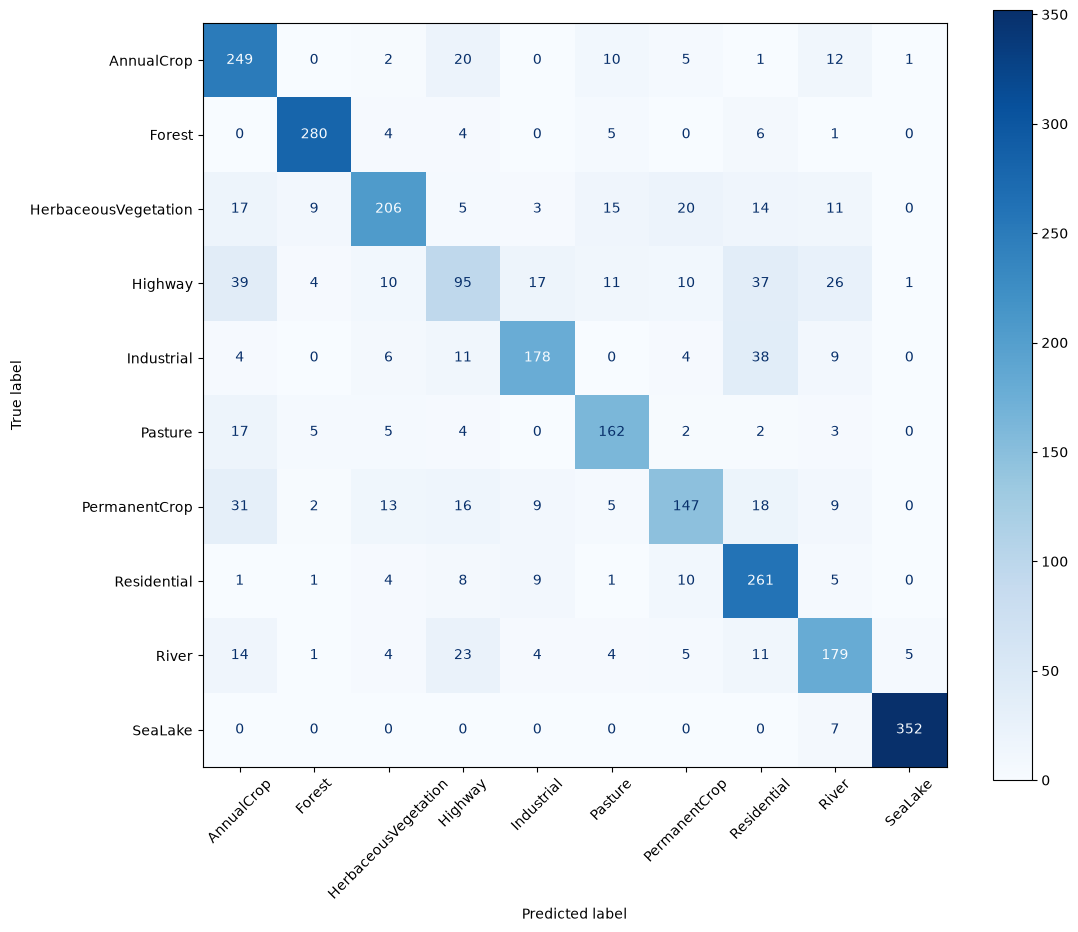

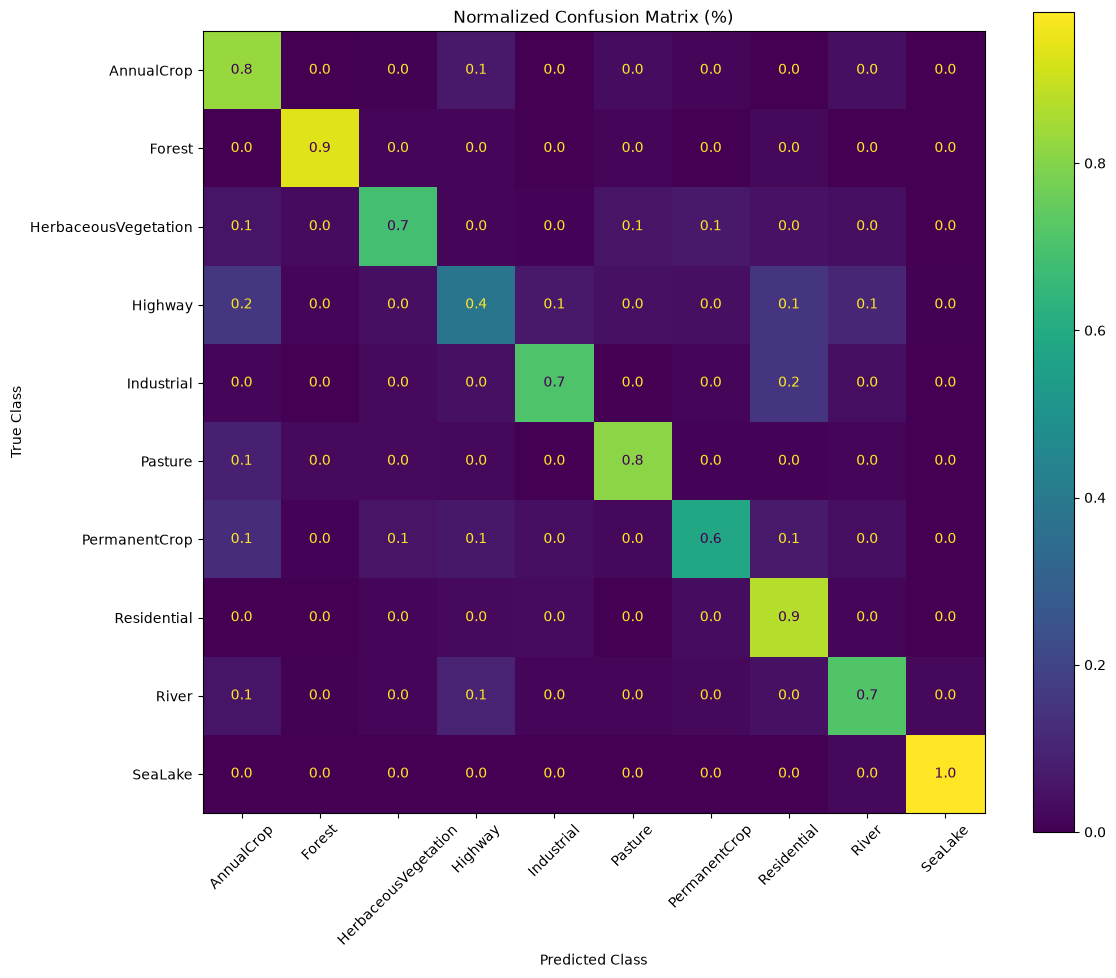

<Figure size 640x480 with 0 Axes>

                      precision    recall  f1-score   support

          AnnualCrop       0.67      0.83      0.74       300
              Forest       0.93      0.93      0.93       300
HerbaceousVegetation       0.81      0.69      0.74       300
             Highway       0.51      0.38      0.44       250
          Industrial       0.81      0.71      0.76       250
             Pasture       0.76      0.81      0.78       200
       PermanentCrop       0.72      0.59      0.65       250
         Residential       0.67      0.87      0.76       300
               River       0.68      0.72      0.70       250
             SeaLake       0.98      0.98      0.98       359

            accuracy                           0.76      2759
           macro avg       0.75      0.75      0.75      2759
        weighted avg       0.76      0.76      0.76      2759



In [ ]:
df = pd.read_csv(DIR_PATH + "test.csv")

class_mapping = (
    df.iloc[:, [1, 2]]
    .drop_duplicates()
    .sort_values(df.columns[1])
)

class_names = class_mapping.iloc[:, 1].tolist()

print(class_mapping)

SatelliteImageClassifier.load_state_dict(
    torch.load(
        "best_resnet50.pth",
        map_location=device,
        weights_only=True
    )
)

cm, test_loss, test_accuracy, y_true, y_pred = test_model(
    SatelliteImageClassifier,
    test_loader,
    costFunction
)


fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=class_names).plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

# Normalize each row by its total number of samples
normalized_cm = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay(
    confusion_matrix=normalized_cm,
    display_labels=class_names
).plot(
    ax=ax,
    cmap="viridis",
    values_format=".1f",
    xticks_rotation=45,
    colorbar=True
)

ax.set_title("Normalized Confusion Matrix (%)")
ax.set_xlabel("Predicted Class")
ax.set_ylabel("True Class")

plt.tight_layout()
plt.show()

ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.show()

print(classification_report(y_true,y_pred,labels=list(range(10)),target_names=class_names,zero_division=0))


In [ ]:
#These are saved ahead of time so we can use them when importing images 1 by 1. Should only be run on the full dataset
#Should only need to be run once since it will output to a file. 
def save_normalization_stats(train_loader, filename="normalization_stats.txt"):
    band_sum = torch.zeros(13, dtype=torch.float64)
    band_sq_sum = torch.zeros(13, dtype=torch.float64)
    total_pixels = 0

    for images, labels in tqdm(train_loader):
        images = images.double()

        band_sum += images.sum(dim=(0, 2, 3))
        band_sq_sum += (images ** 2).sum(dim=(0, 2, 3))

        total_pixels += images.shape[0] * images.shape[2] * images.shape[3]

    band_mean = band_sum / total_pixels
    band_std = torch.sqrt((band_sq_sum / total_pixels - band_mean ** 2))

    # Save as a readable text file: one row per band
    stats = np.column_stack([
        band_mean.numpy(),
        band_std.numpy()
    ])
    np.savetxt(filename,stats,fmt="%.10f",header="mean std")
    print(f"Saved normalization constants to {filename}")

#TODO: this should remain commented out, and only rerun if normalization_stats.txt is lost. It also has to be run on an unnormalized set
#save_normalization_stats(train_loader)